# COVID-19 Chest X-Ray (Synthetic, 3-Class)

Same caveat as the pneumonia notebook (104): real COVID radiograph datasets exist (Cohen et al., BIMCV-COVID19+) but I haven't downloaded them and I don't want to ship a notebook that looks like a clinical model. The images here are synthetic.

This one bumps to **3 classes** (`normal`, `pneumonia`, `covid`) to show the multi-class softmax pipeline. The synthetic difference between "pneumonia" and "covid" is small on purpose — covid radiographs in the real literature are often described as bilateral and peripheral, so I make covid samples have two opacities placed toward the lateral edges, while pneumonia samples have one or two opacities placed anywhere. A small CNN will pick *something* up; that something is the toy structure I drew.

**This is a multi-class pipeline demo on synthetic images. Not a model.**

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

torch.manual_seed(1); np.random.seed(1)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


shape: (270, 64, 64)   counts: [110  90  70]


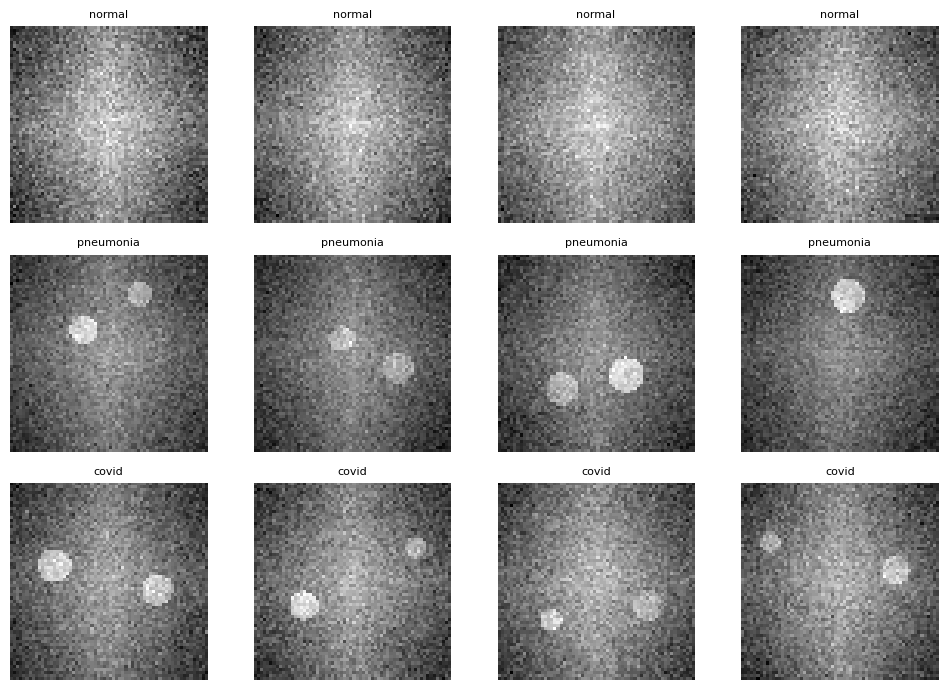

In [2]:
def gen_xray(label, size=64, rng=None):
    rng = rng or np.random
    xx = np.linspace(-1, 1, size); yy = np.linspace(-1, 1, size)
    X, Y = np.meshgrid(xx, yy)
    img = 0.35 + 0.18 * (1 - np.abs(X)) + 0.10 * (1 - np.abs(Y))
    img += rng.normal(0, 0.04, img.shape)
    if label == 1:   # pneumonia: 1-2 opacities anywhere
        for _ in range(rng.randint(1, 3)):
            cx, cy = rng.uniform(-0.7, 0.7, 2)
            r = rng.uniform(0.10, 0.20)
            mask = ((X - cx) ** 2 + (Y - cy) ** 2) < r ** 2
            img[mask] += rng.uniform(0.10, 0.22)
    elif label == 2:  # covid: bilateral peripheral
        for side in [-1, 1]:
            cx = side * rng.uniform(0.45, 0.75)
            cy = rng.uniform(-0.4, 0.4)
            r = rng.uniform(0.10, 0.18)
            mask = ((X - cx) ** 2 + (Y - cy) ** 2) < r ** 2
            img[mask] += rng.uniform(0.08, 0.20)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.RandomState(1)
# imbalanced on purpose — covid was much rarer than the other two in the early-2020 datasets
n_per = {0: 110, 1: 90, 2: 70}
imgs, labels = [], []
for lbl, n in n_per.items():
    for _ in range(n):
        imgs.append(gen_xray(lbl, rng=rng))
        labels.append(lbl)
imgs = np.stack(imgs); labels = np.array(labels)
order = rng.permutation(len(labels))
imgs, labels = imgs[order], labels[order]
print("shape:", imgs.shape, "  counts:", np.bincount(labels))

class_names = ["normal", "pneumonia", "covid"]
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for c in range(3):
    idxs = np.where(labels == c)[0][:4]
    for j, i in enumerate(idxs):
        axes[c, j].imshow(imgs[i], cmap="gray")
        axes[c, j].set_title(class_names[c], fontsize=8)
        axes[c, j].axis("off")
plt.tight_layout(); plt.show()

## Tiny 3-class CNN, weighted loss for the imbalance

In [3]:
class XrayNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64, num_classes))
    def forward(self, x): return self.head(self.feat(x))

x = torch.tensor(imgs).unsqueeze(1); y = torch.tensor(labels, dtype=torch.long)
ds = TensorDataset(x, y)
n_tr = int(0.75 * len(ds))
tr_ds, te_ds = random_split(ds, [n_tr, len(ds) - n_tr], generator=torch.Generator().manual_seed(1))
tr_dl = DataLoader(tr_ds, batch_size=16, shuffle=True)
te_dl = DataLoader(te_ds, batch_size=32)

# inverse-frequency weights — covid is the rarest, give it more weight
counts = np.bincount(labels)
weights = torch.tensor((counts.sum() / counts), dtype=torch.float32, device=device)
print("class weights:", weights.tolist())

model = XrayNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=weights)

for ep in range(8):
    model.train(); total, n = 0, 0
    for xb, yb in tr_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); out = model(xb)
        l = loss_fn(out, yb); l.backward(); opt.step()
        total += l.item() * xb.size(0); n += xb.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

class weights: [2.454545497894287, 3.0, 3.857142925262451]


ep 1  train_loss=1.103


ep 2  train_loss=1.098


ep 3  train_loss=1.098


ep 4  train_loss=1.098


ep 5  train_loss=1.098


ep 6  train_loss=1.098


ep 7  train_loss=1.098


ep 8  train_loss=1.098


In [4]:
model.eval()
ys, ps = [], []
with torch.no_grad():
    for xb, yb in te_dl:
        xb = xb.to(device)
        ps.extend(model(xb).argmax(1).cpu().tolist())
        ys.extend(yb.tolist())

print(classification_report(ys, ps, target_names=class_names))
print("confusion (rows=true, cols=pred):")
print(confusion_matrix(ys, ps))

              precision    recall  f1-score   support

      normal       0.00      0.00      0.00        29
   pneumonia       0.28      1.00      0.44        19
       covid       0.00      0.00      0.00        20

    accuracy                           0.28        68
   macro avg       0.09      0.33      0.15        68
weighted avg       0.08      0.28      0.12        68



confusion (rows=true, cols=pred):
[[ 0 29  0]
 [ 0 19  0]
 [ 0 20  0]]


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

## Same disclaimer, repeated

These images are not chest x-rays. The "covid" class differs from "pneumonia" only by where I chose to paint blobs. Any per-class number the model produces is a comment on that toy structure, not on radiology.

What's actually transferable: the multi-class head, the inverse-frequency loss weighting (genuinely needed because covid was rare in real datasets), and the per-class confusion-matrix readout. That's the part I'd keep.

Real version would use a pretrained chest x-ray backbone (TorchXRayVision is a good starting point), evaluate on at least one external hospital, and include a discussion of dataset leakage — many early COVID x-ray datasets had label leakage from sourcing (covid scans from one institution, normals from another, model learns the institution rather than the disease).